# 📊 Eleições 2026 - Overview

Este notebook fornece uma visão geral dos dados coletados do TSE.

**O que este notebook faz:**
- Lista todos os snapshots disponíveis
- Mostra metadados da coleta
- Exibe candidatos e partidos
- Apresenta estatísticas de seções e eleitorado
- Visualiza estrutura do JSON

> Os gráficos e tabelas são embutidos no arquivo `.ipynb` após execução, sem limpeza posterior.

In [1]:

import json
import glob
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import datetime

# Setup plotting style
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 11
plt.rcParams['axes.titlesize'] = 14
plt.rcParams['figure.dpi'] = 120

# Find repo root and data dir robustly
def find_data_dir():
    candidates = [
        Path("../data"),
        Path("data"),
        Path("./data"),
        Path(__file__).parent / "../data" if '__file__' in globals() else None,
    ]
    # Also try from cwd
    cwd = Path.cwd()
    for p in [cwd / "data", cwd.parent / "data", cwd / "../data", Path("/home/user/eleicoes-data/data")]:
        candidates.append(p)
    for c in candidates:
        if c and c.exists() and list(c.glob("*.json")):
            return c
    # fallback: search recursively up to 3 levels
    for base in [Path.cwd(), Path.cwd().parent, Path("/home/user/eleicoes-data")]:
        for sub in [base, base / "eleicoes-data"]:
            d = sub / "data"
            if d.exists():
                return d
    return Path("../data")

DATA_DIR = find_data_dir()
print(f"📁 Data directory: {DATA_DIR.resolve()}")

files = sorted(DATA_DIR.glob("*.json"))
print(f"📊 Found {len(files)} snapshot files")
if files:
    print(f"   First: {files[0].name}")
    print(f"   Last:  {files[-1].name}")


📁 Data directory: /home/user/eleicoes-data/data
📊 Found 43 snapshot files
   First: presidente_br_20261005_000211Z.json
   Last:  presidente_br_20261014_192215Z.json


In [2]:

def load_snapshot(path):
    with open(path, 'r', encoding='utf-8') as f:
        return json.load(f)

def extract_candidates(snapshot):
    """Flatten TSE payload into list of dicts."""
    rows = []
    payload = snapshot['data']
    for cargo in payload.get('carg', []):
        for agr in cargo.get('agr', []):
            for par in agr.get('par', []):
                for cand in par.get('cand', []):
                    rows.append({
                        'seq': cand.get('seq'),
                        'numero': cand.get('n'),
                        'nome_completo': cand.get('nm'),
                        'nome_urna': cand.get('nmu'),
                        'partido': par.get('sg'),
                        'partido_nome': par.get('nm'),
                        'agregacao': agr.get('nm'),
                        'votos': int(cand.get('vap', 0) or 0),
                        'percentual': float(str(cand.get('pvap', '0')).replace(',', '.') or 0),
                        'percentual_n': float(str(cand.get('pvapn', '0')).replace(',', '.') or 0),
                        'situacao': cand.get('st', ''),
                        'eleito': cand.get('e', ''),
                    })
    rows.sort(key=lambda x: x['votos'], reverse=True)
    return rows

def load_all_snapshots():
    all_data = []
    for fp in sorted(DATA_DIR.glob("*.json")):
        doc = load_snapshot(fp)
        meta = doc['metadata']
        data = doc['data']
        cands = extract_candidates(doc)
        # sections
        s = data.get('s', {})
        v = data.get('v', {})
        e = data.get('e', {})
        all_data.append({
            'file': fp.name,
            'path': fp,
            'scraped_at_utc': meta.get('scraped_at_utc'),
            'scraped_at_brasilia': meta.get('scraped_at_brasilia'),
            'tse_generated': meta.get('tse_file_generated_at'),
            'secoes_total': int(s.get('ts', 0) or 0),
            'secoes_apuradas': int(s.get('st', 0) or 0),
            'pct_apuradas': float(str(s.get('pst', '0')).replace(',', '.') or 0),
            'eleitorado': int(e.get('te', 0) or 0),
            'comparecimento': int(e.get('c', 0) or 0),
            'abstencao': int(e.get('a', 0) or 0),
            'votos_validos': int(v.get('vv', 0) or 0),
            'votos_brancos': int(v.get('vb', 0) or 0),
            'votos_nulos': int(v.get('vn', 0) or 0),
            'candidatos': cands,
            'metadata': meta,
            'raw': doc
        })
    return all_data

# Load once for convenience
all_snapshots = load_all_snapshots()
latest = all_snapshots[-1] if all_snapshots else None
if latest:
    print(f"✅ Latest snapshot: {latest['file']} | {latest['scraped_at_utc']}")
    print(f"   Seções: {latest['secoes_apuradas']}/{latest['secoes_total']} ({latest['pct_apuradas']}%)")


✅ Latest snapshot: presidente_br_20261014_192215Z.json | 2026-10-14T19:22:15Z
   Seções: 499248/499248 (100.0%)


## 1. Listagem de Snapshots

Todos os arquivos em `data/` são snapshots com timestamp único, nunca sobrescritos.

In [3]:

df_files = pd.DataFrame([{
    'arquivo': s['file'],
    'scraped_utc': s['scraped_at_utc'],
    'tse_generated': s['tse_generated'],
    'secoes_apuradas': s['secoes_apuradas'],
    'pct_apuradas': s['pct_apuradas'],
    'votos_validos': s['votos_validos']
} for s in all_snapshots])
df_files['scraped_utc'] = pd.to_datetime(df_files['scraped_utc'])
df_files = df_files.sort_values('scraped_utc')
df_files.head(10)


,arquivo,scraped_utc,tse_generated,secoes_apuradas,pct_apuradas,votos_validos
0,presidente_br_20261005_000211Z.json,2026-10-05 00:02:11+00:00,04/10/2026 20:51:35,474312,95.01,113091045
1,presidente_br_20261005_211048Z.json,2026-10-05 21:10:48+00:00,05/10/2026 12:51:47,499248,100.00,119300788
2,presidente_br_20261006_014342Z.json,2026-10-06 01:43:42+00:00,05/10/2026 12:51:47,499248,100.00,119300788
3,presidente_br_20261006_080819Z.json,2026-10-06 08:08:19+00:00,05/10/2026 12:51:47,499248,100.00,119300788
4,presidente_br_20261006_150400Z.json,2026-10-06 15:04:00+00:00,05/10/2026 12:51:47,499248,100.00,119300788
5,presidente_br_20261006_200849Z.json,2026-10-06 20:08:49+00:00,05/10/2026 12:51:47,499248,100.00,119300788
6,presidente_br_20261006_234539Z.json,2026-10-06 23:45:39+00:00,05/10/2026 12:51:47,499248,100.00,119300788
7,presidente_br_20261007_024213Z.json,2026-10-07 02:42:13+00:00,05/10/2026 12:51:47,499248,100.00,119300788
8,presidente_br_20261007_091504Z.json,2026-10-07 09:15:04+00:00,05/10/2026 12:51:47,499248,100.00,119300788
9,presidente_br_20261007_162825Z.json,2026-10-07 16:28:25+00:00,05/10/2026 12:51:47,499248,100.00,119300788


In [4]:

print(f"Total de snapshots: {len(df_files)}")
print(f"Período: {df_files['scraped_utc'].min()} até {df_files['scraped_utc'].max()}")
print(f"Última apuração: {df_files['pct_apuradas'].iloc[-1]}%")
df_files.tail(10)


Total de snapshots: 43
Período: 2026-10-05 00:02:11+00:00 até 2026-10-14 19:22:15+00:00
Última apuração: 100.0%


,arquivo,scraped_utc,tse_generated,secoes_apuradas,pct_apuradas,votos_validos
33,presidente_br_20261012_223118Z.json,2026-10-12 22:31:18+00:00,05/10/2026 12:51:47,499248,100.0,119300788
34,presidente_br_20261013_030723Z.json,2026-10-13 03:07:23+00:00,05/10/2026 12:51:47,499248,100.0,119300788
35,presidente_br_20261013_102602Z.json,2026-10-13 10:26:02+00:00,05/10/2026 12:51:47,499248,100.0,119300788
36,presidente_br_20261013_174109Z.json,2026-10-13 17:41:09+00:00,05/10/2026 12:51:47,499248,100.0,119300788
37,presidente_br_20261013_215646Z.json,2026-10-13 21:56:46+00:00,05/10/2026 12:51:47,499248,100.0,119300788
38,presidente_br_20261014_004457Z.json,2026-10-14 00:44:57+00:00,05/10/2026 12:51:47,499248,100.0,119300788
39,presidente_br_20261014_052527Z.json,2026-10-14 05:25:27+00:00,05/10/2026 12:51:47,499248,100.0,119300788
40,presidente_br_20261014_102209Z.json,2026-10-14 10:22:09+00:00,05/10/2026 12:51:47,499248,100.0,119300788
41,presidente_br_20261014_151409Z.json,2026-10-14 15:14:09+00:00,05/10/2026 12:51:47,499248,100.0,119300788
42,presidente_br_20261014_192215Z.json,2026-10-14 19:22:15+00:00,05/10/2026 12:51:47,499248,100.0,119300788


## 2. Metadados do Último Snapshot

In [5]:

import pprint
pprint.pprint(latest['metadata'])

# Show raw structure keys
print("\n--- DATA keys ---")
print(list(latest['raw']['data'].keys()))
print("\n--- Sections (s) ---")
print(latest['raw']['data']['s'])
print("\n--- Electorate (e) ---")
print(latest['raw']['data']['e'])
print("\n--- Votes (v) ---")
print(latest['raw']['data']['v'])


{'abrangencia': 'br',
 'cargo': 'Presidente',
 'data_url': 'https://resultados.tse.jus.br/oficial/ele2026/6257/dados/br/br-c0001-e006257-u.json',
 'election_id': '6257',
 'election_turn': '1',
 'page_url': 'https://resultados.tse.jus.br/oficial/app/index.html#/eleicao/6257/uf/br/cargo/1/vis/nominal/resultados',
 'scraped_at_brasilia': '2026-10-14T16:22:15-03:00',
 'scraped_at_utc': '2026-10-14T19:22:15Z',
 'source': 'Tribunal Superior Eleitoral (TSE) - Resultados Oficial',
 'source_bytes': 9349,
 'tse_file_generated_at': '05/10/2026 12:51:47',
 'tse_last_updated_at': '05/10/2026 12:51:05'}

--- DATA keys ---
['ele', 't', 'f', 'sup', 'tpabr', 'cdabr', 'dg', 'hg', 'idg', 'dt', 'ht', 'dv', 'tf', 'and', 'esae', 'mnae', 'carg', 's', 'e', 'v']

--- Sections (s) ---
{'ts': '499248', 'st': '499248', 'pst': '100,00', 'pstn': '100', 'snt': '0', 'psnt': '0,00', 'psntn': '0', 'si': '499207', 'psi': '99,99', 'psin': '99,991787649', 'sni': '41', 'psni': '0,01', 'psnin': '0,008212351', 'sa': '499207'

## 3. Candidatos - Ranking Atual

In [6]:

df_cands = pd.DataFrame(latest['candidatos'])
df_cands = df_cands[['seq', 'numero', 'nome_urna', 'nome_completo', 'partido', 'votos', 'percentual', 'situacao', 'eleito']]
df_cands


,seq,numero,nome_urna,nome_completo,partido,votos,percentual,situacao,eleito
0,1,22,FLAVIO BOLSONARO,FLAVIO NANTES BOLSONARO,PL,56104503,47.03,2º turno,s
1,2,13,LULA,LUIZ INÁCIO LULA DA SILVA,PT,53879538,45.16,2º turno,s
2,3,70,ESCRITOR AUGUSTO CURY,AUGUSTO JORGE CURY,AVANTE,3448569,2.89,Não eleito,n
3,4,14,RENAN SANTOS,RENAN ANTONIO FERREIRA DOS SANTOS,MISSÃO,2675887,2.24,Não eleito,n
4,5,55,RONALDO CAIADO,RONALDO RAMOS CAIADO,PSD,2605148,2.18,Não eleito,n
5,6,30,ZEMA,ROMEU ZEMA NETO,NOVO,326488,0.27,Não eleito,n
6,7,80,SAMARA,SAMARA MARTINS DA SILVA FEITOSA,UP,122911,0.10,Não eleito,n
7,8,16,HERTZ DIAS,HERTZ DA CONCEICAO DIAS,PSTU,43103,0.04,Não eleito,n
8,9,27,CLARIANA BARAO,CLARIANA ZACARKIM BARAO,DC,40043,0.03,Não eleito,n
9,10,21,EDMILSON COSTA,EDMILSON SILVA COSTA,PCB,22693,0.02,Não eleito,n


In [7]:

# Pretty print ranking
for i, row in enumerate(df_cands.itertuples(), 1):
    status = f" [{row.situacao}]" if row.situacao else ""
    print(f"{i:2d}. {row.nome_urna:30s} ({row.partido:10s}) - {row.votos:>10,} votos ({row.percentual:5.2f}%){status}")


 1. FLAVIO BOLSONARO               (PL        ) - 56,104,503 votos (47.03%) [2º turno]
 2. LULA                           (PT        ) - 53,879,538 votos (45.16%) [2º turno]
 3. ESCRITOR AUGUSTO CURY          (AVANTE    ) -  3,448,569 votos ( 2.89%) [Não eleito]
 4. RENAN SANTOS                   (MISSÃO    ) -  2,675,887 votos ( 2.24%) [Não eleito]
 5. RONALDO CAIADO                 (PSD       ) -  2,605,148 votos ( 2.18%) [Não eleito]
 6. ZEMA                           (NOVO      ) -    326,488 votos ( 0.27%) [Não eleito]
 7. SAMARA                         (UP        ) -    122,911 votos ( 0.10%) [Não eleito]
 8. HERTZ DIAS                     (PSTU      ) -     43,103 votos ( 0.04%) [Não eleito]
 9. CLARIANA BARAO                 (DC        ) -     40,043 votos ( 0.03%) [Não eleito]
10. EDMILSON COSTA                 (PCB       ) -     22,693 votos ( 0.02%) [Não eleito]
11. VETERINÁRIO WILSON GRASSI      (DEMOCRATA ) -     16,881 votos ( 0.01%) [Não eleito]
12. RUI COSTA PIMENTA    

## 4. Estatísticas Gerais

Visualização rápida de seções, comparecimento e tipos de voto.

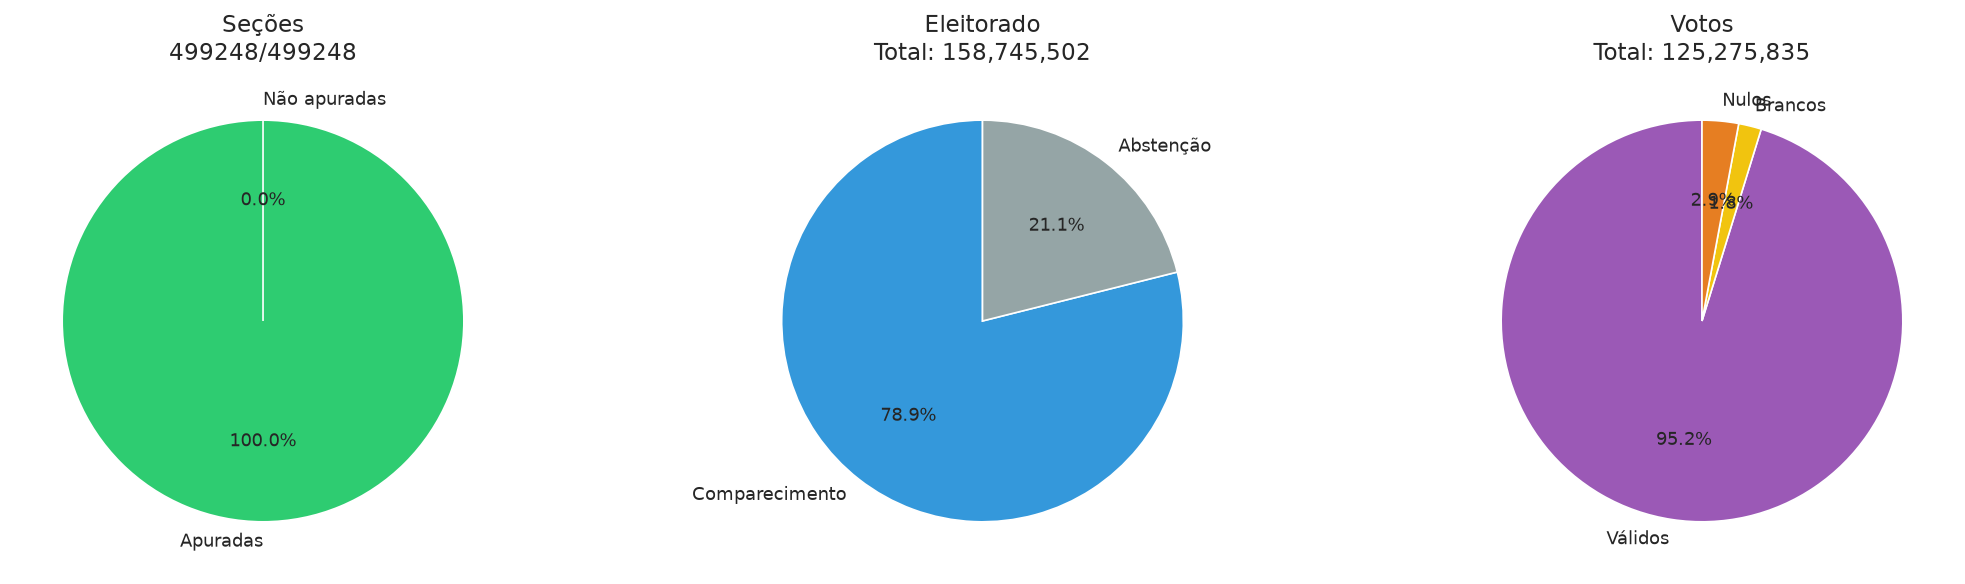

In [8]:

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Seções
axes[0].pie([latest['secoes_apuradas'], latest['secoes_total']-latest['secoes_apuradas']], 
        labels=['Apuradas', 'Não apuradas'], autopct='%1.1f%%', colors=['#2ecc71', '#e74c3c'], startangle=90)
axes[0].set_title(f"Seções\n{latest['secoes_apuradas']}/{latest['secoes_total']}")

# Eleitorado
axes[1].pie([latest['comparecimento'], latest['abstencao']], 
        labels=['Comparecimento', 'Abstenção'], autopct='%1.1f%%', colors=['#3498db', '#95a5a6'], startangle=90)
axes[1].set_title(f"Eleitorado\nTotal: {latest['eleitorado']:,}")

# Votos
axes[2].pie([latest['votos_validos'], latest['votos_brancos'], latest['votos_nulos']], 
        labels=['Válidos', 'Brancos', 'Nulos'], autopct='%1.1f%%', colors=['#9b59b6', '#f1c40f', '#e67e22'], startangle=90)
axes[2].set_title(f"Votos\nTotal: {latest['comparecimento']:,}")

plt.tight_layout()
plt.savefig('overview_stats.png', dpi=150, bbox_inches='tight')  # optional external image
plt.show()


## 5. Estrutura de Dados - Exemplo de Payload

O JSON bruto do TSE contém: `ele` (eleição), `carg` (cargo), `s` (seções), `e` (eleitorado), `v` (votos).

In [9]:

# Show cargo structure
cargo = latest['raw']['data']['carg'][0]
print(f"Cargo: {cargo['nmn']} (cd={cargo['cd']})")
print(f"Número de agregações/partidos: {len(cargo['agr'])}")
for agr in cargo['agr'][:3]:
    par = agr['par'][0]
    cand = par['cand'][0]
    print(f" - {agr['nm']}: {par['sg']} -> {cand['nmu']} ({cand['vap']} votos)")


Cargo: Presidente (cd=1)
Número de agregações/partidos: 12
 - PARTIDO LIBERAL: PL -> FLAVIO BOLSONARO (56104503 votos)
 - PARTIDO SOCIAL DEMOCRÁTICO: PSD -> RONALDO CAIADO (2605148 votos)
 - BRASIL PRONTO PRA MAIS: PT -> LULA (53879538 votos)
